# Проект: поиск по изображениям

Проект предназначается для фотохостинга для профессиональных фотографов «Со Смыслом» (“With Sense”)

На этой площадке пользователи размещают свои фотографии и сопровождают их полным описанием: указывают место съёмок, модель камеры и т. д. Отличительная особенность сервиса — описание: его может предоставить не только тот, кто размещает фотографию, но и другие пользователи портала. Например, для этой фотографии

Данный проект направлен на то, чтобы фотографам было удобнее подбирать референсы. Фотограф вводит описание, а сервис в ответ ему выдет похожую картинку

Целью проекта является разработка модели, которая будет обозначать степень схожести описания и картинки для вывода пользователю наиболее подходящих изображений

Данная цель распадается на несколько задач:
1. Загрузка данных
2. Предобработка данных
3. Исследовательский анализ
4. Подготовка данных к обучению
5. Обучение моделей
6. Тестирование лучшей модели

### Описание данных


В файле `train_dataset.csv` находится информация, необходимая для обучения: имя файла изображения, идентификатор описания и текст описания. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `train_images` содержатся изображения для тренировки модели.

В файле `CrowdAnnotations.tsv` — данные по соответствию изображения и описания, полученные с помощью краудсорсинга. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.
3. Доля людей, подтвердивших, что описание соответствует изображению.
4. Количество человек, подтвердивших, что описание соответствует изображению.
5. Количество человек, подтвердивших, что описание не соответствует изображению.

В файле `ExpertAnnotations.tsv` содержатся данные по соответствию изображения и описания, полученные в результате опроса экспертов. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.

3, 4, 5 — оценки трёх экспертов.

Эксперты ставят оценки по шкале от 1 до 4, где 1 — изображение и запрос совершенно не соответствуют друг другу, 2 — запрос содержит элементы описания изображения, но в целом запрос тексту не соответствует, 3 — запрос и текст соответствуют с точностью до некоторых деталей, 4 — запрос и текст соответствуют полностью.

В файле `test_queries.csv` находится информация, необходимая для тестирования: идентификатор запроса, текст запроса и релевантное изображение. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `test_images` содержатся изображения для тестирования модели.

## Загрузка инструментов

Загрузим требуемые библиотеки

In [1]:
import re
import math
import torch
import os
import pandas as pd
import numpy as np
import torch.nn as nn
import torchvision.models as models
import matplotlib.pyplot as plt
import spacy
from tqdm.notebook import tqdm

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from sentence_transformers import SentenceTransformer
from torchvision import transforms
from PIL import Image

from catboost import CatBoostRegressor

## Исследовательский анализ данных

Считаем наши табличные данные и проверим корректность

In [2]:
crowd_annotations = pd.read_csv('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/CrowdAnnotations.tsv', 
                                sep='\t',
                                header=None,
                                names=['image','query_id','match_part','correspondence','not_correspondence'])
expert_annotations = pd.read_csv('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/ExpertAnnotations.tsv', 
                                 sep='\t',
                                 header=None,
                                 names=['image','query_id','1_rating','2_rating','3_rating'])

In [3]:
train_dataset = pd.read_csv('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/train_dataset.csv')
test_images = pd.read_csv('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/test_images.csv')

In [4]:
test_queries = pd.read_csv('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/test_queries.csv',
                          sep='|')

In [5]:
display(crowd_annotations.head(5))
display(expert_annotations.head(5))
display(train_dataset.head(5))
display(test_images.head(5))
display(test_queries.head(5))

,image,query_id,match_part,correspondence,not_correspondence
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.0,3,0
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.0,0,3
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.0,0,3
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.0,0,3
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.0,0,3


,image,query_id,1_rating,2_rating,3_rating
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2


,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
1,1262583859_653f1469a9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
2,2447284966_d6bbdb4b6e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
4,2621415349_ef1a7e73be.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...


,image
0,3356748019_2251399314.jpg
1,2887171449_f54a2b9f39.jpg
2,3089107423_81a24eaf18.jpg
3,1429546659_44cb09cbe2.jpg
4,1177994172_10d143cb8d.jpg


,Unnamed: 0,query_id,query_text,image
0,0,1177994172_10d143cb8d.jpg#0,"Two blonde boys , one in a camouflage shirt an...",1177994172_10d143cb8d.jpg
1,1,1177994172_10d143cb8d.jpg#1,Two boys are squirting water guns at each other .,1177994172_10d143cb8d.jpg
2,2,1177994172_10d143cb8d.jpg#2,Two boys spraying each other with water,1177994172_10d143cb8d.jpg
3,3,1177994172_10d143cb8d.jpg#3,Two children wearing jeans squirt water at eac...,1177994172_10d143cb8d.jpg
4,4,1177994172_10d143cb8d.jpg#4,Two young boys are squirting water at each oth...,1177994172_10d143cb8d.jpg


Все корректно считалось, теперь проверим на пропуски и дубликаты

In [6]:
crowd_annotations.info()
print()
expert_annotations.info()
print()
train_dataset.info()
print()
test_images.info()
print()
test_queries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   image               47830 non-null  object 
 1   query_id            47830 non-null  object 
 2   match_part          47830 non-null  float64
 3   correspondence      47830 non-null  int64  
 4   not_correspondence  47830 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.8+ MB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image     5822 non-null   object
 1   query_id  5822 non-null   object
 2   1_rating  5822 non-null   int64 
 3   2_rating  5822 non-null   int64 
 4   3_rating  5822 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 227.6+ KB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entrie

In [7]:
display(crowd_annotations.duplicated().sum())
print()
display(expert_annotations.duplicated().sum())
print()
display(train_dataset.duplicated().sum())
print()
display(test_images.duplicated().sum())
print()
display(test_queries.duplicated().sum())

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

Дубликатов и пропусков не было обнаружено

Теперь считаем наши изображения

In [8]:
def read_images(path):
    images = []
    names = []
    for filename in os.listdir(path):
        if filename.endswith('.jpg'):
            images.append(Image.open(path+filename).convert('RGB'))
            names.append(filename)
    
    images = pd.Series(data=images, name='raw')
    names = pd.Series(data=names, name='image')
    return images, names

In [9]:
def show_images(images):
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    for i, img in enumerate(images.sample(5)):
        axes[i].imshow(img)
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

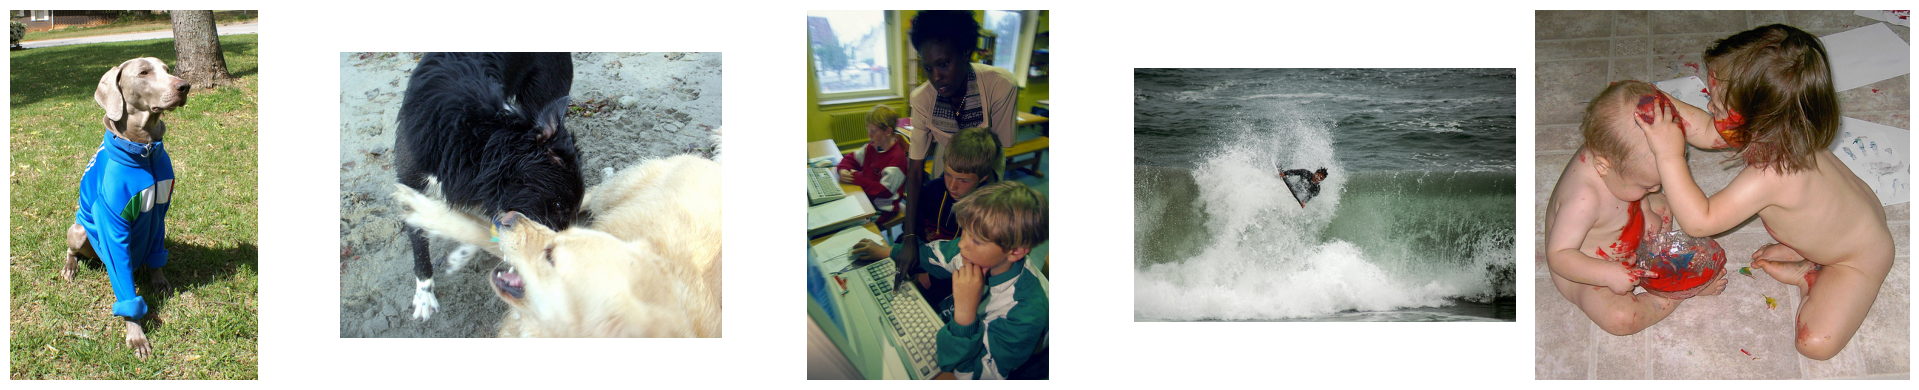

In [10]:
train_images, train_names = read_images('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/train_images/')
show_images(train_images)

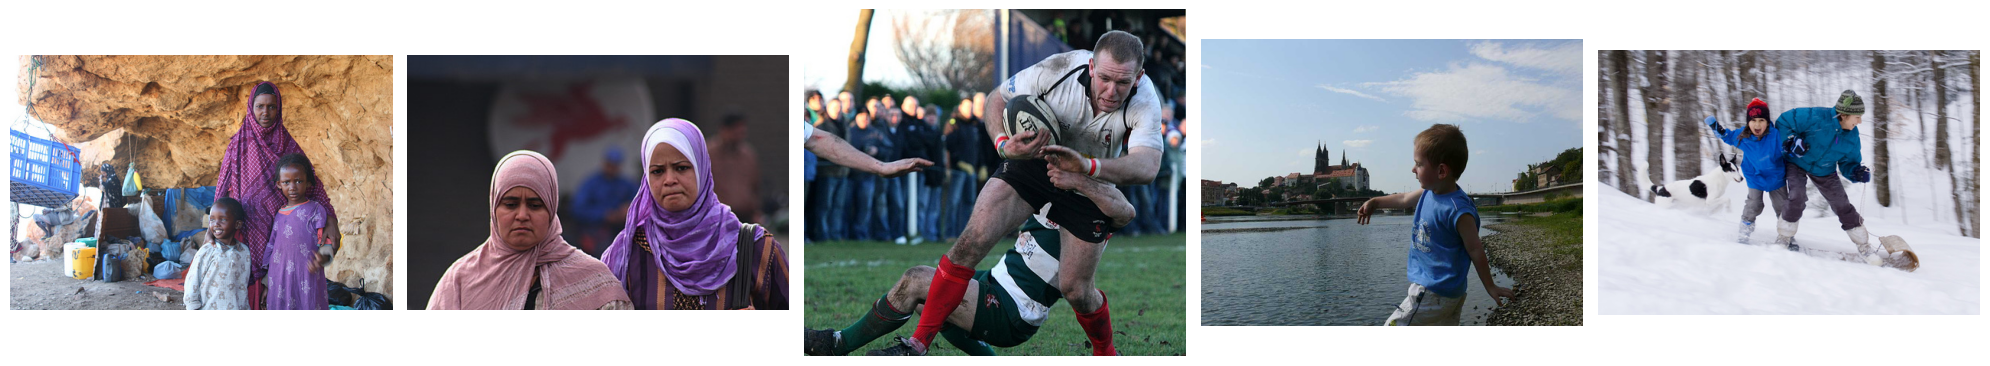

In [11]:
test_images, test_names = read_images('/kaggle/input/datasets/gennadybudaev/dataset-project-5/to_upload/test_images/')
show_images(test_images)

Изображения считались корректно

Посмотрим на описания

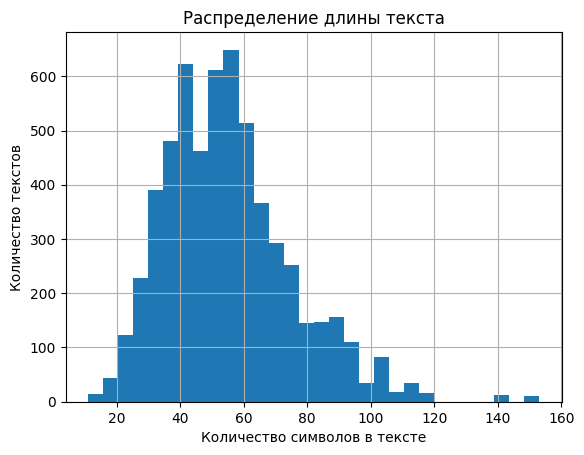

Средняя длина описания:  55.21882514599794


In [12]:
lengths = train_dataset['query_text'].apply(len)
lengths.hist(bins=30)
plt.title('Распределение длины текста')
plt.xlabel('Количество символов в тексте')
plt.ylabel('Количество текстов')
plt.show()
print('Средняя длина описания: ',lengths.mean())

In [13]:
cv = CountVectorizer()

matrix = cv.fit_transform(train_dataset['query_text'])

word_counts = pd.Series(
    matrix.toarray().sum(axis=0),
    index=cv.get_feature_names_out()
).sort_values(ascending=False)

print(word_counts.head(20))

in         2818
the        2539
on         1727
is         1282
and        1212
dog        1161
with       1113
man         996
of          906
two         841
white       699
woman       561
black       521
boy         511
to          501
at          472
wearing     450
water       440
girl        439
an          414
dtype: int64


Наченм составлять нашу целевую переменную, начнем с оценок экспертов, будем использовать обычное усредненное значение, с делением на 3, чтобы степень схожести была между 0 и 1, как нам надо по заданию

In [14]:
expert_annotations['match_part'] = (expert_annotations['1_rating'] + expert_annotations['2_rating'] + expert_annotations['3_rating']-3)/9
expert_rating = expert_annotations.drop(['1_rating','2_rating','3_rating'],axis=1)
display(expert_rating.head())
expert_rating.info()

,image,query_id,match_part
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,0.000000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,0.111111
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,0.111111
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,0.222222
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,0.111111


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image       5822 non-null   object 
 1   query_id    5822 non-null   object 
 2   match_part  5822 non-null   float64
dtypes: float64(1), object(2)
memory usage: 136.6+ KB


Теперь вопспользуемся и оценками с краудсорсинга

In [15]:
crowd_rating = pd.pivot_table(data=crowd_annotations, values='match_part', index=['image','query_id'], aggfunc='mean').reset_index()
display(crowd_rating.head())
crowd_rating.info()

,image,query_id,match_part
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.0
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.0
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.0
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.0
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image       47830 non-null  object 
 1   query_id    47830 non-null  object 
 2   match_part  47830 non-null  float64
dtypes: float64(1), object(2)
memory usage: 1.1+ MB


In [16]:
final_rating = pd.merge(expert_rating,crowd_rating,on=['image','query_id'],how='left')
final_rating = final_rating.rename(columns={'match_part_x': 'expert', 'match_part_y': 'crowd'})
display(final_rating.head())
final_rating.info()

,image,query_id,expert,crowd
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,0.000000,0.0
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,0.111111,0.0
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,0.111111,NaN
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,0.222222,NaN
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,0.111111,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   image     5822 non-null   object 
 1   query_id  5822 non-null   object 
 2   expert    5822 non-null   float64
 3   crowd     2329 non-null   float64
dtypes: float64(2), object(2)
memory usage: 182.1+ KB


По количеству оценок от краудсорсинга после объединения можно сказать, что там было много лишних оценок, которые не относились к данным нам парам изображение-описание, но с этим тоже можно что то придумать, напишем функцию расчета

In [17]:
def special_rate(row):
    if row['crowd']:
        return row['expert']
    else:
        return (row['crowd'] + row['expert'])/2
final_rating['match_part'] = final_rating.apply(special_rate,axis=1)
display(final_rating.head())
final_rating.info()

,image,query_id,expert,crowd,match_part
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,0.000000,0.0,0.000000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,0.111111,0.0,0.055556
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,0.111111,NaN,0.111111
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,0.222222,NaN,0.222222
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,0.111111,NaN,0.111111


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image       5822 non-null   object 
 1   query_id    5822 non-null   object 
 2   expert      5822 non-null   float64
 3   crowd       2329 non-null   float64
 4   match_part  5822 non-null   float64
dtypes: float64(3), object(2)
memory usage: 227.6+ KB


In [18]:
train_df = pd.merge(train_dataset, final_rating.drop(['expert','crowd'],axis=1), on=['image','query_id'],how='left').drop('query_id',axis=1)
display(train_df.head())

,image,query_text,match_part
0,1056338697_4f7d7ce270.jpg,A young child is wearing blue goggles and sitt...,0.000000
1,1262583859_653f1469a9.jpg,A young child is wearing blue goggles and sitt...,0.000000
2,2447284966_d6bbdb4b6e.jpg,A young child is wearing blue goggles and sitt...,0.111111
3,2549968784_39bfbe44f9.jpg,A young child is wearing blue goggles and sitt...,1.000000
4,2621415349_ef1a7e73be.jpg,A young child is wearing blue goggles and sitt...,0.000000


Финальная оценка готова!

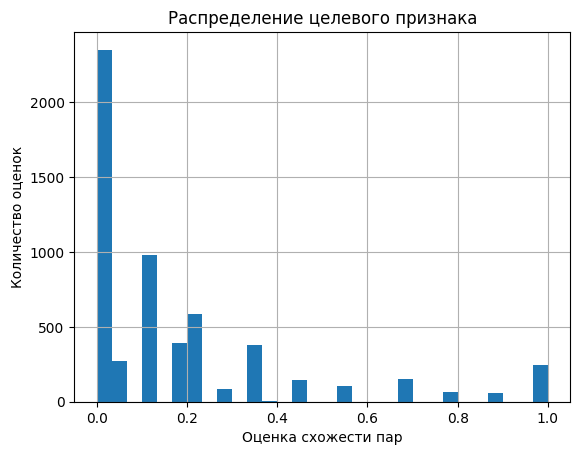

In [19]:
train_df['match_part'].hist(bins=30)
plt.title('Распределение целевого признака')
plt.xlabel('Оценка схожести пар')
plt.ylabel('Количество оценок')
plt.show()

По итогу исследовательского анализа данных можно ответить на ряд вопросов:
1. Дубликатов и пропусков в табличных данных не было обнаружено
3. Изображения считались корректно, стоит отметить, что там очень много картинок с собаками и детьми
4. Был тщательно осмотрен текст, средняя его длина составила примерно 55 символов, распределение длины близко к нормальному, имеет слабую ассиметрию  и легкое уменьшение(по сравнению с 40 и 60) встречаемости длин рядом с 50. Самыми встречаемыми словами, если не брать предлоги стали: dog, man, white, woman, black, также часто встречались слова 'boy' и 'girl', эти слова нам понадобятся в следующем этапе
5. Была составлена таргетная переменная на основе оценок экспертов и краудсорсинговой платформы, к сожалению данные с краудсорсинга не полностью покрывают наш датасет, так что они были задействованы для уточнения уже существующих оценок от экспертов, для тех пар, которые не были оценены краудсорсом мы оставили чисто оценку от экспертов. По поводу распределения таргета можно сказать, что он имеет якровыраженную асимметрию, с пиком в 0, после чего частота встречаемости оценок идет на убыль и происходит легкое возрастание в значении 1 

## Подготовка данных к обучению

В нашем задании было указано, что присутствуют юридические ограничения, запрещены запросы, где упоминаются лица не достигшие 16 лет, поэтому создадим фильтр

In [20]:
stop_words = [
  "baby", "babies", "toddler", "toddlers", "infant", "infants",
  "newborn", "child", "children", "kid", "kids", "minor", "minors",
  "pupil", "pupils", "schoolboy", "schoolgirl",
  "schoolkid", "schoolchildren", "teenager", "preteen",
  "kindergarten", "nursery", "playgroup", "school age","boy","girl"]
img_blacklist = []

In [21]:
def censore_text(row):
    for word in stop_words:
        if word in row['query_text']:
            img_blacklist.append(row['image'])
            return None
    return row['query_text']

In [22]:
def censore_img(row):
    if row['image'] in img_blacklist:
        return None
    else:
        return row['image']

In [23]:
train_df['query_text'] = train_df.apply(censore_text,axis=1)
train_df['image'] = train_df.apply(censore_img,axis=1)

In [24]:
train_df = train_df.dropna().reset_index(drop=True)

In [25]:
display(train_df.head())
train_df.info()

,image,query_text,match_part
0,488590040_35a3e96c89.jpg,A man sleeps under a blanket on a city street .,0.222222
1,3251976937_20625dc2b8.jpg,A woman plays with long red ribbons in an empt...,0.000000
2,1962729184_6996e128e7.jpg,Chinese market street in the winter time .,0.166667
3,3100251515_c68027cc22.jpg,Chinese market street in the winter time .,0.000000
4,370614351_98b8a166b9.jpg,Chinese market street in the winter time .,0.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1481 entries, 0 to 1480
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image       1481 non-null   object 
 1   query_text  1481 non-null   object 
 2   match_part  1481 non-null   float64
dtypes: float64(1), object(2)
memory usage: 34.8+ KB


Начнем векторизацию текстовых запросов

In [26]:
model = SentenceTransformer('all-MiniLM-L6-v2')
nlp = spacy.load('en_core_web_sm')

def vectorize_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z!?. ]', '', text)
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    doc = nlp(text)
    text = ' '.join([token.lemma_ for token in doc])
    return model.encode(text)

train_df['vector_text'] = train_df['query_text'].apply(vectorize_text)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [27]:
display(train_df.head())

,image,query_text,match_part,vector_text
0,488590040_35a3e96c89.jpg,A man sleeps under a blanket on a city street .,0.222222,"[0.047790162, 0.034594905, 0.024265569, 0.1240..."
1,3251976937_20625dc2b8.jpg,A woman plays with long red ribbons in an empt...,0.000000,"[0.0841355, -0.067780726, -0.006662665, 0.0108..."
2,1962729184_6996e128e7.jpg,Chinese market street in the winter time .,0.166667,"[-0.028931223, 0.049557578, 0.033316273, 0.093..."
3,3100251515_c68027cc22.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093..."
4,370614351_98b8a166b9.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093..."


Теперь векторизуем изображения

In [28]:
train_img_dict = dict(zip(train_names, train_images))
train_df['to_vector'] = train_df['image'].map(train_img_dict)
display(train_df.head())

,image,query_text,match_part,vector_text,to_vector
0,488590040_35a3e96c89.jpg,A man sleeps under a blanket on a city street .,0.222222,"[0.047790162, 0.034594905, 0.024265569, 0.1240...",<PIL.Image.Image image mode=RGB size=500x337 a...
1,3251976937_20625dc2b8.jpg,A woman plays with long red ribbons in an empt...,0.000000,"[0.0841355, -0.067780726, -0.006662665, 0.0108...",<PIL.Image.Image image mode=RGB size=500x333 a...
2,1962729184_6996e128e7.jpg,Chinese market street in the winter time .,0.166667,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=500x284 a...
3,3100251515_c68027cc22.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=500x332 a...
4,370614351_98b8a166b9.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=371x500 a...


In [29]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
resnet = models.resnet18(pretrained=True)
for param in resnet.parameters():
    param.requires_grad_(False) 

modules = list(resnet.children())[:-2]
resnet = nn.Sequential(*modules)
resnet = resnet.to(device)

resnet.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Con

In [30]:
norm = transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    norm,
]) 

In [31]:
def vectorize_img(img):
    image_tensor = preprocess(img)
    image_tensor = image_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        output_tensor = resnet(image_tensor).flatten()
    return output_tensor.cpu().numpy()

In [32]:
tqdm.pandas()
train_df['vector_img'] = train_df['to_vector'].progress_apply(vectorize_img)
display(train_df.head(10))

  0%|          | 0/1481 [00:00<?, ?it/s]

,image,query_text,match_part,vector_text,to_vector,vector_img
0,488590040_35a3e96c89.jpg,A man sleeps under a blanket on a city street .,0.222222,"[0.047790162, 0.034594905, 0.024265569, 0.1240...",<PIL.Image.Image image mode=RGB size=500x337 a...,"[0.11976479, 1.9785922, 2.7892585, 3.3556147, ..."
1,3251976937_20625dc2b8.jpg,A woman plays with long red ribbons in an empt...,0.000000,"[0.0841355, -0.067780726, -0.006662665, 0.0108...",<PIL.Image.Image image mode=RGB size=500x333 a...,"[0.01566643, 0.0, 0.0, 0.01743169, 0.04016486,..."
2,1962729184_6996e128e7.jpg,Chinese market street in the winter time .,0.166667,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=500x284 a...,"[0.6466871, 1.3742037, 1.5152413, 2.1111305, 2..."
3,3100251515_c68027cc22.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=500x332 a...,"[0.04117742, 0.0, 0.3458483, 0.24155173, 0.250..."
4,370614351_98b8a166b9.jpg,Chinese market street in the winter time .,0.000000,"[-0.028931223, 0.049557578, 0.033316273, 0.093...",<PIL.Image.Image image mode=RGB size=371x500 a...,"[0.81526434, 1.1759502, 0.0, 0.08826418, 1.024..."
5,3256043809_47258e0b3e.jpg,A soccer ball is above the head of a man weari...,0.000000,"[-0.010928257, 0.10566606, -0.0841291, -0.0306...",<PIL.Image.Image image mode=RGB size=500x334 a...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
6,3630332976_fdba22c50b.jpg,A soccer ball is above the head of a man weari...,0.000000,"[-0.010928257, 0.10566606, -0.0841291, -0.0306...",<PIL.Image.Image image mode=RGB size=500x333 a...,"[0.0, 0.0, 0.7891814, 2.0701003, 1.2868744, 1...."
7,114051287_dd85625a04.jpg,A man and woman look back at the camera while ...,0.000000,"[-0.027419062, 0.04267367, -0.10958105, -0.039...",<PIL.Image.Image image mode=RGB size=450x295 a...,"[0.0571766, 0.32098365, 0.65005165, 0.81459177..."
8,2575647360_f5de38c751.jpg,A man and woman look back at the camera while ...,0.111111,"[-0.027419062, 0.04267367, -0.10958105, -0.039...",<PIL.Image.Image image mode=RGB size=500x375 a...,"[0.0, 0.0, 0.0, 0.0, 0.055607483, 0.62832874, ..."
9,307327914_f98f576adb.jpg,A man and woman look back at the camera while ...,0.055556,"[-0.027419062, 0.04267367, -0.10958105, -0.039...",<PIL.Image.Image image mode=RGB size=500x375 a...,"[0.0, 0.0, 0.44362375, 0.0, 0.0, 0.0, 0.0, 0.0..."


In [33]:
matrix = np.stack(train_df['vector_img'].values).astype(np.float32)

img_df = pd.DataFrame(matrix, index=train_df.index, columns=[f'img_{i}' for i in range(matrix.shape[1])])

In [34]:
matrix = np.stack(train_df['vector_text'].values).astype(np.float32)

text_df = pd.DataFrame(matrix, index=train_df.index, columns=[f'text_{i}' for i in range(matrix.shape[1])])

Надо проскалировать наши данные

In [35]:
normalizer_text = Normalizer()
normalizer_img = Normalizer()

In [36]:
text_norm = normalizer_text.fit_transform(text_df)
img_norm = normalizer_img.fit_transform(img_df)

text_df = pd.DataFrame(data=text_norm,columns=text_df.columns)
img_df = pd.DataFrame(data=img_norm,columns=img_df.columns)

Пришло время конкатонировать наши векторы для обучения

In [37]:
final_train = img_df.join(text_df).join(train_df.drop(['vector_text','vector_img'],axis=1))
display(final_train.head())
final_train.info()

,img_0,img_1,img_2,img_3,img_4,img_5,img_6,img_7,img_8,img_9,...,text_378,text_379,text_380,text_381,text_382,text_383,image,query_text,match_part,to_vector
0,0.000437,0.007214,0.010170,0.012235,0.003842,0.000000,0.000000,0.001198,0.012292,0.017095,...,-0.058080,-0.008560,-0.049531,-0.050724,-0.093702,0.042536,488590040_35a3e96c89.jpg,A man sleeps under a blanket on a city street .,0.222222,<PIL.Image.Image image mode=RGB size=500x337 a...
1,0.000052,0.000000,0.000000,0.000058,0.000134,0.000930,0.000000,0.000000,0.000000,0.000000,...,-0.023707,0.059891,-0.061380,-0.017092,0.030583,0.029779,3251976937_20625dc2b8.jpg,A woman plays with long red ribbons in an empt...,0.000000,<PIL.Image.Image image mode=RGB size=500x333 a...
2,0.002344,0.004981,0.005492,0.007652,0.008791,0.005411,0.004146,0.004370,0.009186,0.005754,...,-0.056871,0.016206,-0.034888,-0.059552,-0.157090,0.119561,1962729184_6996e128e7.jpg,Chinese market street in the winter time .,0.166667,<PIL.Image.Image image mode=RGB size=500x284 a...
3,0.000136,0.000000,0.001142,0.000798,0.000827,0.000000,0.002240,0.000000,0.000456,0.001921,...,-0.056871,0.016206,-0.034888,-0.059552,-0.157090,0.119561,3100251515_c68027cc22.jpg,Chinese market street in the winter time .,0.000000,<PIL.Image.Image image mode=RGB size=500x332 a...
4,0.003115,0.004493,0.000000,0.000337,0.003916,0.005191,0.004302,0.001555,0.003252,0.001376,...,-0.056871,0.016206,-0.034888,-0.059552,-0.157090,0.119561,370614351_98b8a166b9.jpg,Chinese market street in the winter time .,0.000000,<PIL.Image.Image image mode=RGB size=371x500 a...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1481 entries, 0 to 1480
Columns: 25476 entries, img_0 to to_vector
dtypes: float32(25472), float64(1), object(3)
memory usage: 144.0+ MB


Разделим наши данные на тренировочную и валидационную выборки, будем использовать определенный метод, который позволит сделать так, чтобы если какое то конкретное изображение попало в тренировочную выборку, то в валидационную оно не попадет и наоборот

In [38]:
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
train_indices, val_indices = next(gss.split(X=final_train.drop(columns=['match_part']), y=final_train['match_part'], groups=final_train['image']))
train, val = final_train.loc[train_indices], final_train.loc[val_indices]

In [39]:
y_train = train['match_part']
X_train = train.drop(['image','query_text','match_part','to_vector'],axis=1)

y_val = val['match_part']
X_val = val.drop(['image','query_text','match_part','to_vector'],axis=1)

У нас будут обучаться 3 модели: линейная регрессия, катбуст и полносвязная нейронная сеть, начнем с первой. При обучении будем использовать метрику RMSE так как она оастается в одной размерности с таргетом

In [40]:
model1 = LinearRegression()
model1.fit(X_train, y_train)
preds1 = model1.predict(X_val)

In [41]:
print('RMSE для линейной регрессии: ',math.sqrt(mean_squared_error(y_val,preds1)))

RMSE для линейной регрессии:  0.4423778929537359


Теперь обучим катбуст

In [42]:
model2 = CatBoostRegressor(
    random_state=42,
    iterations=100,
    learning_rate=0.01,
    depth=6,
    loss_function='RMSE',
    task_type='GPU'
)
model2.fit(X_train, y_train)
preds2 = model2.predict(X_val)

0:	learn: 0.2929370	total: 420ms	remaining: 41.6s
1:	learn: 0.2924580	total: 662ms	remaining: 32.4s
2:	learn: 0.2919471	total: 897ms	remaining: 29s
3:	learn: 0.2915602	total: 1.13s	remaining: 27.1s
4:	learn: 0.2911369	total: 1.37s	remaining: 26.1s
5:	learn: 0.2907057	total: 1.62s	remaining: 25.4s
6:	learn: 0.2901475	total: 1.88s	remaining: 24.9s
7:	learn: 0.2897889	total: 2.11s	remaining: 24.3s
8:	learn: 0.2893585	total: 2.37s	remaining: 23.9s
9:	learn: 0.2889659	total: 2.62s	remaining: 23.6s
10:	learn: 0.2885295	total: 2.86s	remaining: 23.2s
11:	learn: 0.2881381	total: 3.12s	remaining: 22.9s
12:	learn: 0.2876924	total: 3.37s	remaining: 22.6s
13:	learn: 0.2871967	total: 3.62s	remaining: 22.2s
14:	learn: 0.2867281	total: 3.86s	remaining: 21.9s
15:	learn: 0.2862231	total: 4.12s	remaining: 21.6s
16:	learn: 0.2857406	total: 4.37s	remaining: 21.4s
17:	learn: 0.2852444	total: 4.61s	remaining: 21s
18:	learn: 0.2848373	total: 4.86s	remaining: 20.7s
19:	learn: 0.2844812	total: 5.11s	remaining: 

In [43]:
preds2 = model2.predict(X_val)
print('RMSE для катбуства: ',math.sqrt(mean_squared_error(y_val,preds2)))

RMSE для катбуства:  0.27917687194944274


Теперь пришло время для нейронной сети

In [44]:
X_train_n = torch.FloatTensor(X_train.values)
X_val_n = torch.FloatTensor(X_val.values)
y_train_n = torch.FloatTensor(y_train.values)
y_val_n = torch.FloatTensor(y_val.values)

In [45]:
class Net(nn.Module):
    def __init__(self, n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_hidden_neurons_3, n_out_neurons):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(n_in_neurons, n_hidden_neurons_1)
        self.bn1 = nn.BatchNorm1d(n_hidden_neurons_1)
        self.fc2 = nn.Linear(n_hidden_neurons_1, n_hidden_neurons_2)
        self.bn2 = nn.BatchNorm1d(n_hidden_neurons_2)
        self.fc3 = nn.Linear(n_hidden_neurons_2, n_hidden_neurons_3)
        self.bn3 = nn.BatchNorm1d(n_hidden_neurons_3)
        self.fc4 = nn.Linear(n_hidden_neurons_3, n_out_neurons)

    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.fc3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.fc4(x)
        return x

n_in_neurons = X_train.shape[1]
n_hidden_neurons_1 = 500
n_hidden_neurons_2 = 100
n_hidden_neurons_3 = 50
n_out_neurons = 1

In [46]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_epochs = 1000
net = Net(n_in_neurons, n_hidden_neurons_1, n_hidden_neurons_2, n_hidden_neurons_3, n_out_neurons)
net = net.to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=0.01,weight_decay=0.1)
loss = nn.MSELoss() 

X_train_n = X_train_n.to(device)
y_train_n = y_train_n.to(device)
X_val_n = X_val_n.to(device)
y_val_n = y_val_n.to(device)

for epoch in range(num_epochs):
    net.train()
    optimizer.zero_grad()
    preds = net.forward(X_train_n)
    loss_value = loss(preds, y_train_n)
        
    with torch.no_grad():
        train_rmse = torch.sqrt(loss(torch.expm1(preds),y_train_n))

    loss_value.backward()
        
    optimizer.step()

    net.eval()
    with torch.no_grad():
        val_preds = net.forward(X_val_n)
        val_mse = loss(torch.expm1(val_preds), y_val_n)
        val_rmse = torch.sqrt(val_mse)
    if (epoch+1)%100==0:
        print(val_rmse.item(), ' эпоха ', epoch+1)
            
print('RMSE на тестовой выборке: ',val_rmse.item())

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([1045])) that is different to the input size (torch.Size([1045, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([436])) that is different to the input size (torch.Size([436, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


0.28664788603782654  эпоха  100
0.2881809175014496  эпоха  200
0.28818029165267944  эпоха  300
0.28818002343177795  эпоха  400
0.28818002343177795  эпоха  500
0.28818002343177795  эпоха  600
0.28818002343177795  эпоха  700
0.28818002343177795  эпоха  800
0.28818002343177795  эпоха  900
0.28818002343177795  эпоха  1000
RMSE на тестовой выборке:  0.28818002343177795


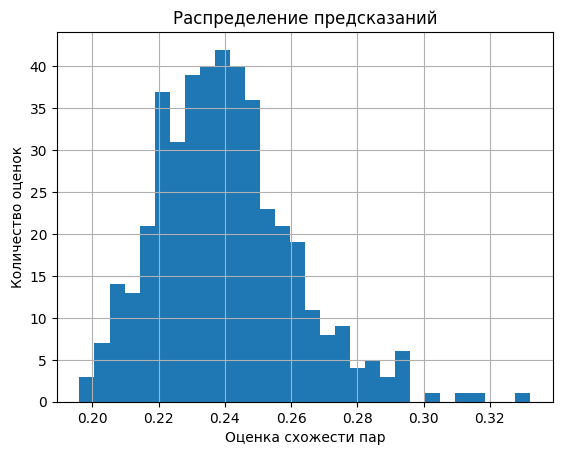

In [47]:
preds_for_hist = pd.Series(data=preds2,name=preds)
preds_for_hist.hist(bins=30)
plt.title('Распределение предсказаний')
plt.xlabel('Оценка схожести пар')
plt.ylabel('Количество оценок')
plt.show()

По итогу обучения моделей можно сказать, что лучше всего себя показал катбуст со значением RMSE = 0.25453202781384043, не намного, но он обошел две другие модели, хотя все равно точность получается плохая. По итогу распределение получилось не особо похожее на реальную картину, хотя распределение предсказаний тоже имеет ярковыраженную ассиматрию, модель максимально все усреднила, нет предсказаний равных 0 и 1, по большей части все предсказания находятся на отрезке (0,07,0,325)

Давайте протекстируем в реальных условиях нашу модель

In [48]:
test_queries = test_queries['query_text']

In [55]:
def test(df, images, names):
    test_text = df.sample(10).reset_index(drop=True)

    vector_images = images.apply(vectorize_img)
    
    matrix = np.stack(vector_images.values).astype(np.float32)
    
    img_df = pd.DataFrame(matrix, index=vector_images.index, columns=[f'img_{i}' for i in range(matrix.shape[1])])
    img_norm = normalizer_img.transform(img_df)
    img_df = pd.DataFrame(data=img_norm,columns=img_df.columns)
    
    
    for text in test_text:
        print(text)
        censority = True
        for word in stop_words:
            if word in text:
                censority = False
        if censority==False:
            print('This image is unavailable in your country in compliance with local laws')
            continue
        else:
            vector = vectorize_text(text)
            matrix = np.stack([vector]).astype(np.float32) 
        
            text_df = pd.DataFrame(matrix,columns=[f'text_{i}' for i in range(matrix.shape[1])])
            text_df_repeat = pd.DataFrame(np.tile(text_df.values,(len(images),1)),columns=text_df.columns)
    
            text_norm = normalizer_text.transform(text_df_repeat)
            text_df_repeat = pd.DataFrame(data=text_norm,columns=text_df.columns)
            
            search = img_df.join(text_df_repeat)
            preds = model2.predict(search)
            preds = pd.Series(data=preds,name='match_part')
            final = search.join(preds).join(names)
            best_row = final['match_part'].idxmax()
        
            img = images[best_row]
            
            plt.imshow(img)
            plt.axis('off')
            plt.show()

A group of six men stand in a circle playing instruments in a wooded parking lot .


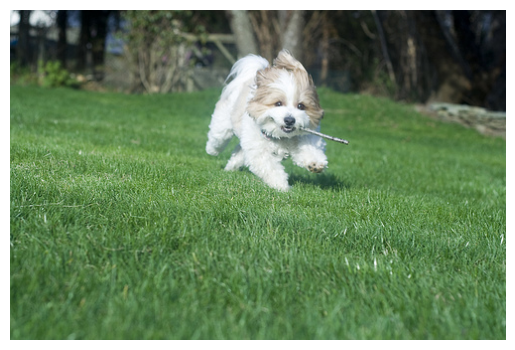

The black dog has a toy in its mouth and a person stands nearby .


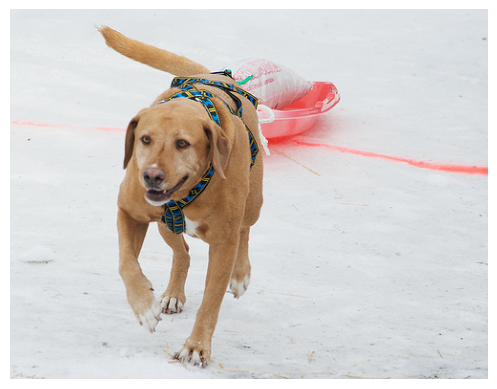

Two dogs are standing next to each other , and the white dog has a stick in its mouth .


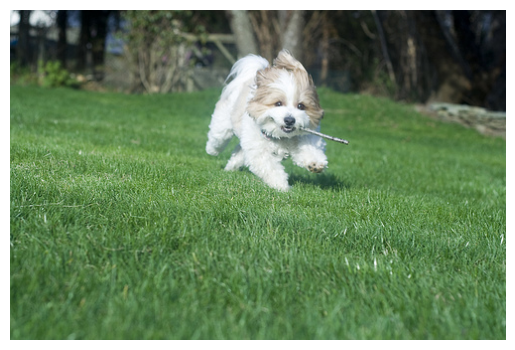

A little boy plays with a basketball and a toy basketball hoop .
This image is unavailable in your country in compliance with local laws
Two girls look on at birthday girl blowing out candles as mother stands by
This image is unavailable in your country in compliance with local laws
A small boy wearing glasses stands on a rope and holds two ropes with his hands .
This image is unavailable in your country in compliance with local laws
A man with something orange on his helmet riding a bike in a busy setting .


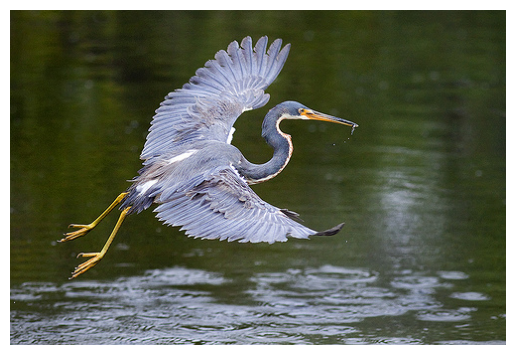

Two dogs playing together in the snow .


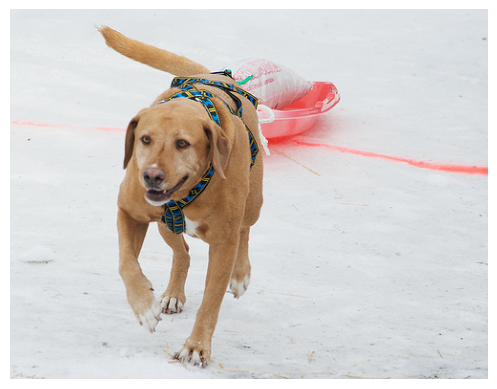

Three boys are standing in a row along an upraised wall and rail , each a level higher than the one before .
This image is unavailable in your country in compliance with local laws
a brown and white dog standing on the street wearing a hat , shirt and jeans .


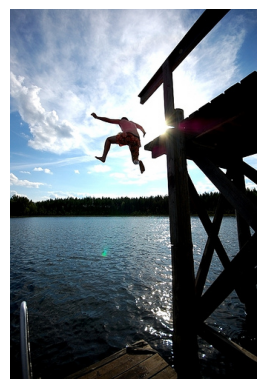

In [56]:
test(test_queries, test_images, test_names)

Ни одна картинка не попала точно в свое описание - крайне удручающий результат, могу предположить, что он связан с инструментарием, предложенным в данном проекте, так как он не в полной мере подходит для задачи, которую перед нами ставят, либо малым количеством картинок в тестовой выборке

По итогу на протяжении выполнения проекта были загружены данные, считали они корректно, на этапе предобработки данных дубликатов и пропусков не было обнаружено. В качестве оценки мы взяли усредненную оценку экспертов. Текст и изображения были векторизованы, на них мы обучили три модели - линейную регрессию, катбуст и полносвязную нейронку, все модели показали плохое качество, быть может есть какая то ошибка на этапе обработки данных, в частности изображений. Была написана функция для тестирования модели, которая выбирает рандомно 10 запросов и подбирает к каждому из них наиболее подходящую картинку из 100 в тестовой выборке. Итоговая модель показала себя очень плохо, так как ни в один из запросов не попала точно в цель, возможно это произошло из за ошибки на одном из этапов проекта, либо из за не совсем подходящих инструментов, которые диктует нам условие проекта. также возможным фактором может быть то. что в датасете с изображениями слишкмо много фото с собаками